# Exercice 1 : Régression - Prédiction du tarif Uber

**Objectif:** Prédire le prix d'un trajet Uber à partir de la distance, l'heure et le jour de la semaine.

**Dataset:** Uber Fare Prediction Dataset (Kaggle)

In [ ]:
# Importation des bibliotheques
import pandas as pd # pour manipuler les fichiers excel 
import numpy as np # pour les calculs mathematiques et les tableaux 
import matplotlib.pyplot as plt # pour creer les graphiques 
from sklearn.model_selection import train_test_split
# train_test_split : Fonction pour diviser les donnees en ensemble d'entraînement et de test
from sklearn.linear_model import LinearRegression
# LinearRegression : Modele de regression lineaire (ligne droite)
from sklearn.ensemble import RandomForestRegressor
# RandomForestRegressor : Modele de foret aleatoire (combinaison d'arbres de decision)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Metriques : Fonctions pour evaluer la performance du modele (MAE, RMSE, R^2).
# sklearn = la bibliotheque de machine learning la plus populaire en Python scikit-learn 
print("Bibliothèques importées avec succès!")

Bibliothèques importées avec succès!


In [ ]:
# Chargement du dataset
data = pd.read_csv('../data/uber.csv')

# Afficher les  5 premieres lignes
print("=== Premières lignes ===")
print(data.head()) 

# Informations sur les colonnes
print("\n=== Informations sur les colonnes  ===")
print(data.info())

# Valeurs manquantes
print("\n=== Valeurs manquantes ===")
print(data.isnull().sum())

=== Premières lignes ===
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647     

In [ ]:
# Calculer la distance entre pickup et dropoff (Formule de Haversine)
# dropoff_longitude / dropoff_latitude / pickup_longitude / pickup_latitude
# pickup point de depart et dropoff point d'arrivee
def haversine(lon1, lat1, lon2, lat2):
    """
    Calculer la distance en km entre deux points GPS.
    """
    # Convertir les degres en radians
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    
    # Formule de Haversine
    dlon = lon2 - lon1 # Difference de longitude en radians
    dlat = lat2 - lat1 # Difference de latitude en radians
    # Formule de Haversine 
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    # angle centrale entre les 2 points 
    c = 2 * np.arcsin(np.sqrt(a))
    r = 6371  # Rayon de la Terre en km
    return c * r # la distance en km

# Appliquer la fonction pour creer la colonne 'distance'
data['distance'] = haversine(
    data['pickup_longitude'], data['pickup_latitude'],
    data['dropoff_longitude'], data['dropoff_latitude']
)

print("Colonne 'distance' créée!")
print(data[['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'distance']].head())

Colonne 'distance' créée!
   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   distance  
0  1.683323  
1  2.457590  
2  5.036377  
3  1.661683  
4  4.475450  


In [ ]:
# Nettoyage: Supprimer les valeurs manquantes
data = data.dropna()

# Supprimer les valeurs aberrantes 
# Garde seulement les trajets avec un prix positif (> 0). Enleve les valeurs aberrantes (negatives)
data = data[data['fare_amount'] > 0]

# Convertir pickup_datetime en datetime
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])

# Creer des variables derivees:extraire  heure et jour de la semaine
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek

print("Nettoyage terminé!")
print(f"Nombre de lignes après nettoyage: {len(data)}")
print(data[['fare_amount', 'distance', 'hour', 'day_of_week' , 'pickup_datetime']].head())

Nettoyage terminé!
Nombre de lignes après nettoyage: 199977
   fare_amount  distance  hour  day_of_week           pickup_datetime
0          7.5  1.683323    19            3 2015-05-07 19:52:06+00:00
1          7.7  2.457590    20            4 2009-07-17 20:04:56+00:00
2         12.9  5.036377    21            0 2009-08-24 21:45:00+00:00
3          5.3  1.661683     8            4 2009-06-26 08:22:21+00:00
4         16.0  4.475450    17            3 2014-08-28 17:47:00+00:00


In [ ]:
# Separation des features (X) et de target  (y)
# les caracteristiques / features / v.d'entrees 
X = data[['distance', 'hour', 'day_of_week']]
# target / v.de sortie qu'on veut predire 
y = data['fare_amount'] 

# Séparation Train/Test (80% Train, 20% Test)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
) # random_state fixe l'hazard pour garder les memes resultats a chaque execution

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (159981, 3)
X_test: (39996, 3)
y_train: (159981,)
y_test: (39996,)


In [ ]:
# Importation du modèle
from sklearn.linear_model import LinearRegression

# Création une instance du modèle LinearRegression
# trouver une droite qui minimise l'erreur entre les prédictions et les vraies valeurs
lr = LinearRegression()
# Entraîne le modele sur les donnees d'entraînement
# Le modele calcule les coefficients w car y = w * x + b(intercept) .
lr.fit(X_train, y_train)

# Prédictions sur les données de test
y_pred_lr = lr.predict(X_test)

print("Modèle LinearRegression entraîné!")
print(f"Coefficients (distance, hour, day_of_week): {lr.coef_}")
print(f"Intercept: {lr.intercept_:.2f}")

Modèle LinearRegression entraîné!
Coefficients (distance, hour, day_of_week): [ 0.00065973 -0.02876221  0.03022581]
Intercept: 11.64


In [ ]:
# evaulation du modèle
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calcul des métriques
mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
# coefficient de determination  1=parfait , 0=moyenne 
r2 = r2_score(y_test, y_pred_lr)

print("=== Évaluation LinearRegression ===")
print(f"MAE  = {mae:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"R²   = {r2:.4f}")

=== Évaluation LinearRegression ===
MAE  = 6.02
RMSE = 9.64
R²   = 0.0015


In [ ]:
# Amelioration de modele avec Random Forest
from sklearn.ensemble import RandomForestRegressor

# Modele Random Forest avec 100 arbre de decision 
rf = RandomForestRegressor(n_estimators=100, random_state=42)
# Entraîne les 100 arbres sur les donnees
rf.fit(X_train, y_train)

# Predictions 
# Chaque arbre fait une prediction, puis on prend la moyenne.
y_pred_rf = rf.predict(X_test)

# Évaluation
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("=== Évaluation Random Forest ===")
print(f"MAE  = {mae_rf:.2f}")
print(f"RMSE = {rmse_rf:.2f}")
print(f"R²   = {r2_rf:.4f}")

=== Évaluation Random Forest ===
MAE  = 2.68
RMSE = 5.24
R²   = 0.7042


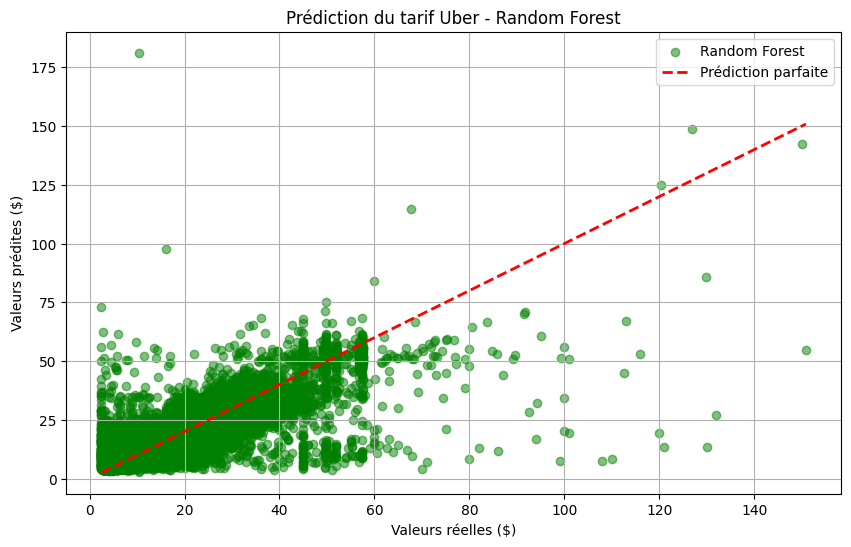

In [ ]:
# visualisation des resultats 
import matplotlib.pyplot as plt

# Comparaison des prédictions vs valeurs réelles
plt.figure(figsize=(10, 6))
# nuage des points 
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='green', label='Random Forest')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Prédiction parfaite')
plt.xlabel('Valeurs réelles ($)')
plt.ylabel('Valeurs prédites ($)')
plt.title('Prédiction du tarif Uber - Random Forest')
plt.legend()
plt.grid(True)
plt.show()
# Si les points sont proches de la ligne rouge, le modèle est bon
# Si les points sont éloignés, le modèle fait des erreurs

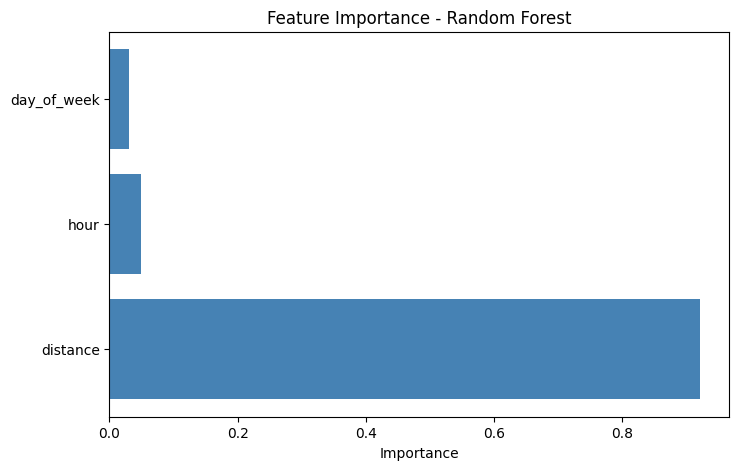

distance: 0.9210
hour: 0.0486
day_of_week: 0.0305


In [ ]:
# Feature Importance (RandomForest)
import matplotlib.pyplot as plt

features = ['distance', 'hour', 'day_of_week']
importances = rf.feature_importances_

plt.figure(figsize=(8, 5))
plt.barh(features, importances, color='steelblue')
plt.xlabel('Importance')
plt.title('Feature Importance - Random Forest')
plt.show()

# Affichage
for feat, imp in zip(features, importances):
    print(f"{feat}: {imp:.4f}")

In [ ]:
# Tableau comparatif
comparaison = pd.DataFrame({
    'Modèle': ['LinearRegression', 'RandomForest'],
    'MAE': [mae, mae_rf],
    'RMSE': [rmse, rmse_rf],
    'R²': [r2, r2_rf]
})

print("=== Comparaison des Modèles ===")
print(comparaison.to_string(index=False))

=== Comparaison des Modèles ===
          Modèle      MAE     RMSE       R²
LinearRegression 6.024607 9.635979 0.001459
    RandomForest 2.675632 5.244700 0.704188


## Conclusion - Exercice 1

### Résultats:
| Modèle | MAE | RMSE | R² |
| :--- | :--- | :--- | :--- |
| LinearRegression | 6.024607| 9.635979| 0.001459 |
| RandomForest | 2.675632 | 5.244700 | 0.704188 |

### Interprétation:
- **Random Forest** est plus performant que **LinearRegression** (R² plus élevé).
- Le modèle capture mieux les relations non-linéaires entre la distance, l'heure et le prix.
- **Améliorations possibles:**
  - Ajouter plus de features (ex: passenger_count, jour de la semaine)
  - Tester d'autres modèles (XGBoost, GradientBoosting)
  - Feature engineering (ex: heure de pointe)